# Na jakich sygnałach opiera się pierwsza decyzja (swipe)? Porównanie bloków cech

**Teza do sprawdzenia.** *Demografia i zainteresowania dominują, a deklarowany styl życia i bio dodają niewiele.*

**Zastrzeżenie o zakresie.** Mamy zapis swipe'ów, a nie to, na co ludzie patrzą. „Opierają się” czytamy więc jako „statystycznie wiążą się z prawym swipe'em” i „mają wartość predykcyjną” (ile dodają do przewidywania ponad inne cechy). Notebook nie mówi nic o motywach ani o przyczynowości. Wynik dotyczy prawego swipe'a (nie matcha, nie wynajmu), wąskiej próby (głównie Wrocław, młodzi użytkownicy) i jest **eksploracyjny**: ujednolicony schemat zbudowano po obejrzeniu wyników H1–H3a. Notebook **nie rozstrzyga** konfirmacyjnych hipotez H1 i H3a w ich prerejestrowanych metrykach (tu jest inna metryka: przyrost AUC w CV po nadawcach).

### Jak czytać ten notebook
1. Idź od góry do dołu: każda komórka kodu ma nad sobą jedno zdanie wyjaśnienia, a logika siedzi w modułach `rentfriends.unified*`.
2. Każdy wykres ma podpis (numer, co pokazuje, jak czytać) i zdanie „co to znaczy”.
3. Główna miara to **przyrost AUC** bloku cech: o ile lepiej model odróżnia prawe swipe'y od lewych, gdy dostaje ten blok. Zero = „nic nie dodaje”.
4. Liczby w opisach i we wnioskach (sekcja 7) są wyliczane z wyników, nie wpisane z ręki.
5. Żaden wiersz danych, klucz użytkownika ani bio nie jest wyświetlany; pilnuje tego komórka-strażnik `guard`.

## 0. Parametry

Jedna komórka z parametrami. `FAST=False` to pełny przebieg (1000 powtórzeń bootstrapu, 200 permutacji), zwykle z gotowego cache.

In [10]:
import time
import warnings

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.figure import Figure

from rentfriends import unified
from rentfriends import unified_figs as uf

warnings.filterwarnings("ignore")
T_START = time.perf_counter()

FAST = False  # True: n_boot=100, n_perm=10 (szybki podgląd, przedziały zgrubne)
SEED = 0  # ziarno dodatkowych rachunków w notebooku; run_all używa własnych ziaren (0, 1, ...)
N_BOOT = 1000  # powtórzenia bootstrapu po nadawcach
N_PERM = 200  # permutacje nulla
N_CV_SEEDS = 3  # tyle razy powtarzamy podział na foldy (ziarna 0, 1, 2)
CV_SEEDS = tuple(range(N_CV_SEEDS))
np.random.seed(SEED)

Funkcje pomocnicze: zapis liczb po polsku oraz **strażnik**, który odmawia pokazania tabeli z kolumnami identyfikującymi użytkownika lub bio.

In [11]:
import io

FORBIDDEN = {"user_key", "target_user_key", "s_key", "r_key", "bio"}


def guard(df: pd.DataFrame) -> pd.DataFrame:
    bad = FORBIDDEN & {str(c).lower() for c in df.columns}
    assert not bad, f"tabela zawiera zakazane kolumny: {bad}"
    return df


def show(df: pd.DataFrame) -> None:
    display(guard(df))


def md(text: str) -> None:
    display(Markdown(text))


def pl(x: float, nd: int = 3, sign: bool = False) -> str:
    s = f"{x:+.{nd}f}" if sign else f"{x:.{nd}f}"
    return s.replace(".", ",").replace("-", "\u2212")


def ci(est: float, lo: float, hi: float, nd: int = 3, sign: bool = True) -> str:
    return f"{pl(est, nd, sign)} [{pl(lo, nd, sign)}; {pl(hi, nd, sign)}]"


def cis(b: str, v: tuple) -> str:
    # 3 miejsca po przecinku dla demografii, 4 dla małych bloków
    return ci(*v, nd=3 if b == "demography" else 4)


def figure(fig: Figure) -> None:
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=130)
    display(Image(buf.getvalue()))

Ustawienie katalogu i sprawdzenie danych. Jupyter uruchamia notebook z folderu `notebooks/`, a ścieżki w kodzie są względem **katalogu głównego repozytorium**, więc najpierw tam przechodzimy. Notebook czyta **lokalne, pełne** tabele `users`, `profile_history` i `swipes` (z kolumnami profilu: styl życia, zainteresowania, bio) z `data/interim/unified/`. Tych plików nie ma w repozytorium (dane nigdy w gicie), więc bez nich notebook zatrzyma się z komunikatem. Uwaga: `csv_to_parquet.py` zapisuje tylko okrojone kolumny H2 do `data/processed/` i **nie wystarcza** (zob. `docs/notes/unified-analysis.md`).

In [12]:
import os
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(root)
DATA_DIR = Path("data/interim/unified")
needed = ("users", "profile_history", "swipes")
missing = [f"{n}.parquet" for n in needed if not (DATA_DIR / f"{n}.parquet").exists()]
if missing:
    raise FileNotFoundError(
        f"Brak plików w {root / DATA_DIR}: {', '.join(missing)}. To lokalne, pełne tabele "
        "(poza gitem); trzeba je dostać od osoby, która je przygotowała, i położyć w tym folderze."
    )
print("Katalog repozytorium i dane lokalne: OK")

Katalog repozytorium i dane lokalne: OK


## 1. Dane i próba

Anonimizowane dane RentFriends (aplikacja typu Tinder do szukania współlokatora). Jednostką jest skierowany swipe A→B, wynikiem prawy swipe. Cechy profilu bierzemy według stanu z dnia swipe'a (reguła as-of). Konta z Hyderabadu wykluczono (D10). Nie ma zdjęć ani wiedzy, jak wyglądał feed.

Tabelę swipe'ów budujemy w pamięci (`d`; nigdy jej nie wyświetlamy), a całą analizę liczy jedna funkcja `run_all`. Jej wynik (same agregaty) trafia do cache, więc kolejne uruchomienia są szybkie.

In [13]:
d, flow_raw = unified.build_unified_table()
res = unified.run_all(
    n_boot=N_BOOT,
    n_perm=N_PERM,
    fast=FAST,
    n_cv_seeds=N_CV_SEEDS,
    d=d,
    flow=flow_raw,
    cache_dir="data/interim/unified/cache",
)
meta = res["meta"]
pair, recv = res["compare_pair"], res["compare_receiver"]
sens, sex, desc = res["sensitivity"], res["sex_summary"], res["descriptives"]
N_ROWS = meta["n_rows"]

# Strażnik: żadna tabela wynikowa nie ma kolumn identyfikujących.
for obj in [*pair.values(), *recv.values(), sens, *sex.values(), *desc.values()]:
    guard(obj)
md(
    f"Parametry przebiegu: n_boot={meta['n_boot']}, n_perm={meta['n_perm']}, "
    f"powtórzeń CV={meta['n_cv_seeds']}, wierszy w analizie: {N_ROWS:,}.".replace(",", " ")
)

Parametry przebiegu: n_boot=1000  n_perm=200  powtórzeń CV=3  wierszy w analizie: 93 717.

**Tabela 1.** Lejek próby: ile swipe'ów zostaje po kolejnych krokach.

In [14]:
flow = desc["flow"].copy()
flow["n_swipes"] = flow["n_swipes"].map(lambda v: f"{v:,}".replace(",", " "))
show(flow)

,krok,n_swipes
0,wszystkie swipe'y na profile,95 144
1,po usunięciu Hyderabadu (D10),94 295
2,po complete-case (analiza),93 717


**Tabela 2.** Opis nadawców (jeden wiersz na nadawcę; kategorie poniżej 5 osób zasłonięte).

In [15]:
s = desc["sample"].copy()
s["odsetek"] = s["odsetek"].map(
    lambda v: "—" if pd.isna(v) else f"{100 * v:.1f}%".replace(".", ",")
)
show(s.rename(columns={"zmienna": "Zmienna", "kategoria": "Kategoria", "odsetek": "Udział"}))

,Zmienna,Kategoria,Udział
0,plec_nadawcy,F,"56,1%"
1,plec_nadawcy,M,"42,7%"
2,plec_nadawcy,O,"1,2%"
3,wiek_nadawcy,18-20,"59,5%"
4,wiek_nadawcy,21-23,"20,6%"
5,wiek_nadawcy,27+,"10,6%"
6,wiek_nadawcy,24-26,"9,3%"
7,miasto_nadawcy,Wrocław,"36,7%"
8,miasto_nadawcy,inne,"22,1%"
9,miasto_nadawcy,Warszawa,"16,7%"


**Uwaga o stylu życia (ważna dla interpretacji).** Poniżej odsetek znanych wartości każdego pola na profilach odbiorców w próbie analitycznej. Pola `cleanliness` i `noise_level` są znane w ok. 99% przypadków, **zarówno przed, jak i po uzupełnieniu z tagów (D13)**; D13 podnosi za to `daily_routine` (33→57%) i `smoking` (30→72%). To **zgadza się z codebookiem** (braki 1,0% i 1,2% w surowej tabeli użytkowników); dokumentowane 74–81% braków dotyczy *innych* pól, więc nie ma tu sprzeczności podstaw liczenia.

Czy te dwa pola mają wartości domyślne, **nie jest sprawdzone**. Za domyślnością nie przemawia brak skoku po D13 ani rozkład wartości, który według niezależnej recenzji (nie liczony w tym notebooku) nie jest jednopunktowy: `cleanliness` FT 56%, VT 31%, R 13%; `noise_level` M 53%, Q 34%, R 9%, P 3%. Skoro tylko te dwa pola są prawie zawsze znane, `lifestyle_agree_ratio` opiera się głównie na nich. Wniosek o stylu życia czytamy więc ostrożnie: pomiar jest niepełny i być może zaszumiony.

In [16]:
lm = desc["lifestyle_missing"].copy()
known = lm.set_index("pole")
hi_fields = known.index[known["odsetek_znanych_po_d13"] > 0.9].tolist()
lo_vals = known.loc[~known.index.isin(hi_fields), "odsetek_znanych_po_d13"]
tab = pd.DataFrame(
    {
        "Pole": lm["pole"],
        "Znane przed D13": lm["odsetek_znanych_przed_d13"].map(lambda v: f"{100 * v:.0f}%"),
        "Znane po D13": lm["odsetek_znanych_po_d13"].map(lambda v: f"{100 * v:.0f}%"),
    }
)
show(tab)
md(
    f"Pola znane w >90% przypadków: **{', '.join(hi_fields)}**; pozostałe pola są znane "
    f"w {100 * lo_vals.min():.0f}–{100 * lo_vals.max():.0f}% przypadków (po D13)."
)

,Pole,Znane przed D13,Znane po D13
0,daily_routine,33%,57%
1,lifestyle,38%,38%
2,work_from_home,29%,35%
3,cleanliness,99%,99%
4,noise_level,99%,99%
5,smoking,30%,72%
6,alcohol,27%,27%


Pola znane w >90% przypadków: **cleanliness, noise_level**; pozostałe pola są znane w 27–72% przypadków (po D13).

**Rys. 1.** Kompletność pól stylu życia na profilach odbiorców (po D13). *Jak czytać:* długość słupka to odsetek swipe'ów, w których pole jest znane. *Uwaga:* dwa prawie pełne pola to `cleanliness` i `noise_level`; przyczyny nie znamy.

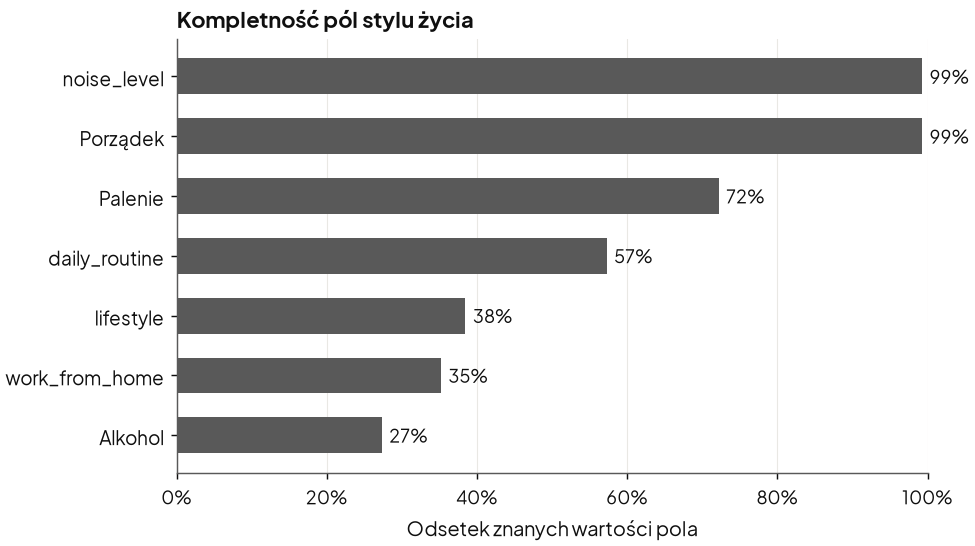

In [17]:
figure(uf.fig_lifestyle_missing(desc["lifestyle_missing"]))

**Co to znaczy:** deklarowany styl życia jest mierzony nierówno (dwa pola prawie pełne, reszta w większości pusta), więc jego niski wkład trzeba czytać ostrożnie.

## 2. Pytania i hipotezy ze statusem

| Pytanie | Status |
|---|---|
| Q1. Czy styl życia dodaje mniej do przewidywania niż wiek i zainteresowania? (H1) | konfirmacyjna w H1 (niepotwierdzona tam); tu tylko sprawdzamy spójność w jednolitym schemacie |
| Q2. Czy bio (jego obecność i długość) wiąże się z prawym swipe'em? (H3a) | konfirmacyjna w H3a; tu tylko spójność |
| Q3. Jak zgodność płci pary wiąże się z prawym swipe'em? (H2) | **eksploracyjna**: wzór zobaczyliśmy przed postawieniem hipotezy |
| Q4. Czy demografia ma większy przyrost niż zainteresowania, styl życia i bio? (teza) | **eksploracyjna** w tej ujednoliconej wersji |
| Q5. Czy zainteresowania wnoszą coś ponad demografię: jako podobieństwo pary, i jako cecha odbiorcy? | eksploracyjna |

Demografia (a zwłaszcza płeć) jest w tym notebooku **zawsze eksploracyjna**. Użyte tu słowa „spójne z” oznaczają zgodność z hipotezą w analizie eksploracyjnej, a nie jej potwierdzenie.

## 3. Metoda w prostych słowach

**Co porównujemy.** Cztery bloki cech pary (nadawca A, profil B): *demografia* (płeć jako komórka nadawca×odbiorca, wiek, różnica wieku), *zainteresowania* (podobieństwo i liczba wspólnych tagów), *styl życia* (zgodność pól i tagów), *bio* (czy jest, jak długie). We wszystkich modelach są też dwie kontrole: to samo miasto i inne miasto.

> **Ramka 1: szansa i OR.** Szansa (odds) to p/(1−p). Iloraz szans (OR) porównuje szanse w dwóch grupach: OR = 2 znaczy „dwa razy większa szansa”, OR = 1 „bez różnicy”, OR < 1 „mniejsza”.

> **Ramka 2: klastrowanie po nadawcy.** Ten sam użytkownik oddaje wiele swipe'ów, więc swipe'y nie są niezależne. Przedziały ufności liczymy, losując **całych nadawców**, a nie pojedyncze swipe'y. Inaczej przedziały byłyby zbyt wąskie.

> **Ramka 3: AUC i predykcja poza próbą.** AUC to szansa, że losowy prawy swipe dostanie wyższy wynik modelu niż losowy lewy. 0,5 = rzut monetą, 1 = ideał. Liczymy je tylko na danych, których model nie widział przy uczeniu.

> **Ramka 4: CV po nadawcach.** Dane dzielimy na 5 części tak, by wszystkie swipe'y jednego nadawcy trafiały do tej samej części. Sprawdzamy więc model na **nowych nadawcach**. (W sekcji 5.3 robimy też wariant kontrolny, w którym razem trafiają swipe'y na ten sam profil, czyli CV po odbiorcach.)

> **Ramka 5: null z przetasowania.** Kolumny bloku mieszamy losowo między wierszami i powtarzamy całą procedurę. Dostajemy przyrost, jaki daje sam szum. Realny przyrost ma sens, jeśli go wyraźnie przekracza. Uwaga: dodanie *jakiejkolwiek* kolumny szumu zwykle lekko **obniża** AUC poza próbą, więc średnia nulla jest ujemna, a „przekracza null” oznacza w praktyce „jest powyżej zera” (zob. 5.3).

> **Ramka 6: bootstrap po nadawcach dla różnic.** Wielokrotnie losujemy nadawców ze zwracaniem i liczymy przyrosty od nowa; z rozrzutu bierzemy przedział 95%. Robimy to także dla **różnic** między blokami, bo to różnica odpowiada na pytanie „który blok dodaje więcej”.

**Miary przyrostu.** *Własny* = pełny model minus pełny model bez bloku (co blok dodaje ponad wszystkie inne). *Ponad demografię* = demografia plus blok minus sama demografia. *Sam* = blok minus same kontrole.

## 4. Wyniki

### 4.1 Płeć pary: wzór asymetryczny (eksploracyjnie)

**Rys. 2.** Odsetek prawych swipe'ów w komórkach płeć nadawcy × płeć odbiorcy. *Jak czytać:* wyższa wartość = częściej prawy swipe; paski to przedziały 95% (bootstrap po nadawcach). Komórki z n<50 są oznaczone i nie podlegają interpretacji. *Uwaga:* płeć odbiorcy miesza preferencję nadawców z popularnością profili.

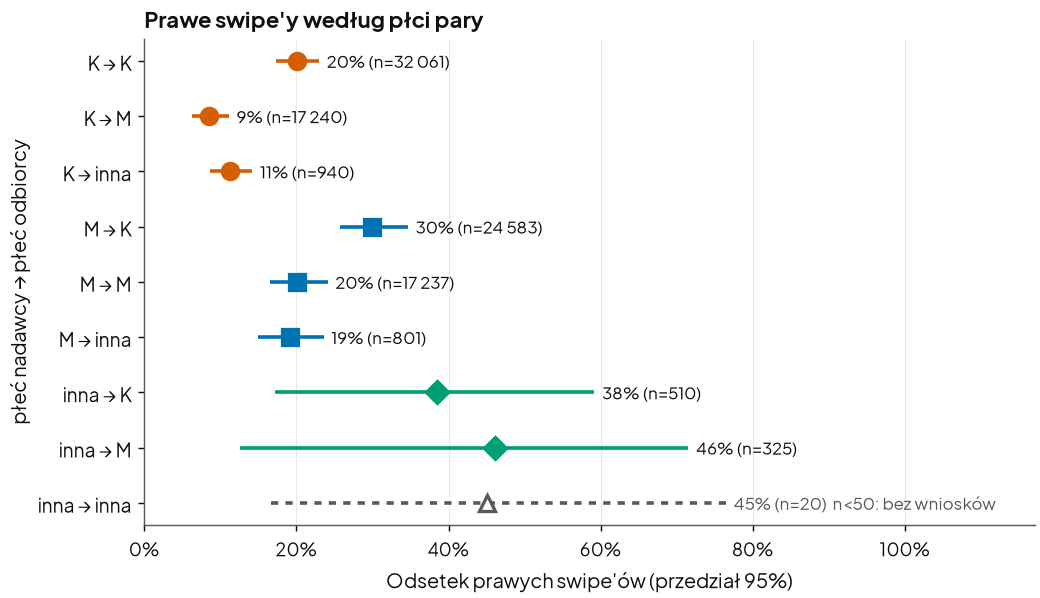

In [18]:
figure(uf.fig_sex_matrix(sex["matrix"]))

**Tabela 3.** Iloraz szans „ta sama płeć vs inna płeć” osobno dla płci nadawcy (OR po korekcie o wiek i miasto; błędy klastrowane po nadawcy i odbiorcy). Eksploracyjne.

In [19]:
od = sex["odds"].copy()
od["OR (z kontrolami) [95% CI]"] = [
    ci(r.or_adj, r.lo_adj, r.hi_adj, 2, False) for r in od.itertuples()
]
od["Interpretacja"] = np.where(od["reportable"], "raportowane", "brak wniosku (n<50 nadawców)")
OR = od.set_index("sender_sex")
show(
    od[["sender_sex", "n_senders", "OR (z kontrolami) [95% CI]", "Interpretacja"]].rename(
        columns={"sender_sex": "Płeć nadawcy", "n_senders": "Nadawcy"}
    )
)

,Płeć nadawcy,Nadawcy,OR (z kontrolami) [95% CI],Interpretacja
0,F,871,"2,44 [1,91; 3,12]",raportowane
1,M,659,"0,66 [0,54; 0,80]",raportowane
2,O,28,"1,14 [0,47; 2,76]",brak wniosku (n<50 nadawców)


In [20]:
m = sex["matrix"].set_index(["sender_sex", "receiver_sex"])
or_f, or_m = pl(OR.loc["F", "or_adj"], 2), pl(OR.loc["M", "or_adj"], 2)


def rate(a: str, b: str) -> str:
    return f"{100 * m.loc[(a, b), 'rate']:.0f}%"


md(
    "**Co to znaczy (eksploracyjnie):** nadawczynie częściej swipe'ują w prawo profile kobiet "
    f"(OR {or_f}), nadawcy częściej profile kobiet niż mężczyzn (OR dla tej samej płci {or_m}). "
    "Wzór jest asymetryczny, więc jeden wspólny efekt „ta sama płeć” byłby mylący. Odsetek "
    f"prawych: K→K {rate('F', 'F')}, K→M {rate('F', 'M')}, M→K {rate('M', 'F')}, "
    f"M→M {rate('M', 'M')}. Ile z tego to *zgodność*, a ile zwykła różnica aktywności nadawców "
    "i popularności profili, pokazuje sekcja 4.4."
)

**Co to znaczy (eksploracyjnie):** nadawczynie częściej swipe'ują w prawo profile kobiet (OR 2,44), nadawcy częściej profile kobiet niż mężczyzn (OR dla tej samej płci 0,66). Wzór jest asymetryczny, więc jeden wspólny efekt „ta sama płeć” byłby mylący. Odsetek prawych: K→K 20%, K→M 9%, M→K 30%, M→M 20%. Ile z tego to *zgodność*, a ile zwykła różnica aktywności nadawców i popularności profili, pokazuje sekcja 4.4.

### 4.2 Główny wynik: przyrosty bloków
**Rys. 3** to jedyny rysunek, który niesie tezę.

**Rys. 3.** Własny przyrost AUC każdego bloku (pełny model minus pełny bez bloku) z przedziałem 95% (bootstrap po nadawcach). *Jak czytać:* lewy panel w pełnej skali, prawy to powiększenie małych przyrostów (demografia poza skalą, strzałka); zero = blok nic nie dodaje. *Uwaga:* pasek nulla to **null przyrostu PONAD demografię** (przetasowany blok dodany do samej demografii), a nie null przyrostu własnego, więc to tylko orientacyjny poziom szumu, a nie test dla zaznaczonych punktów.

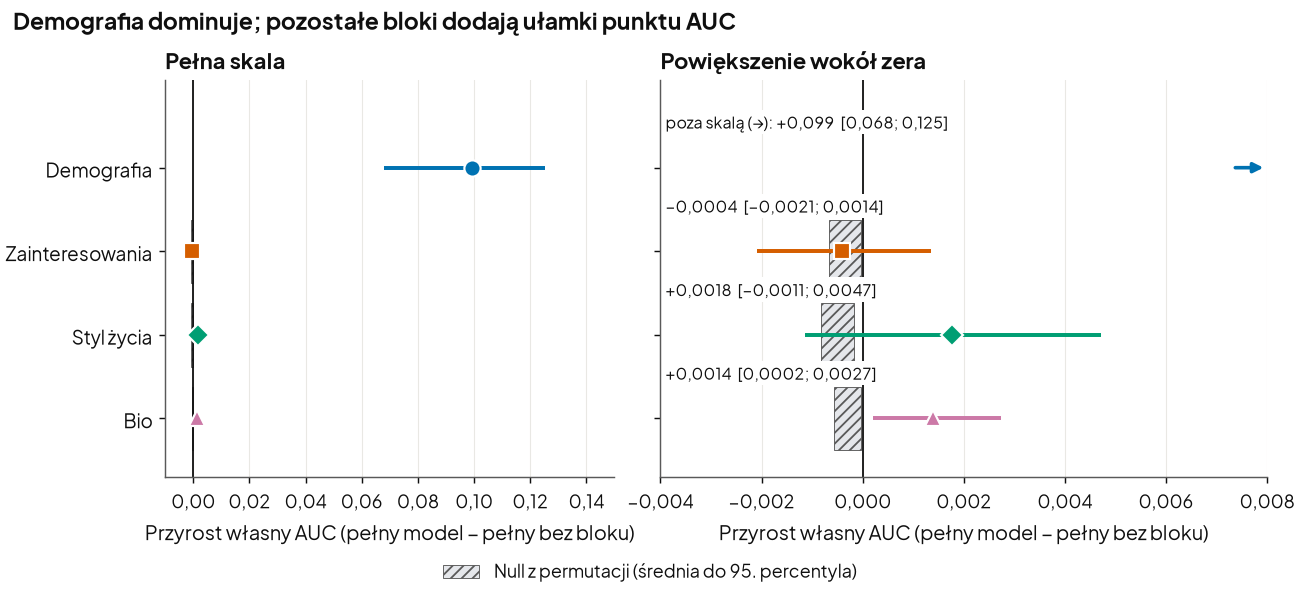

In [21]:
figure(uf.fig_block_increments(pair["contrasts"], pair["null"]))

**Tabela 4.** Przyrosty AUC bloków (wariant `pair`, CV po nadawcach powtórzone dla trzech podziałów; przedziały: bootstrap po nadawcach) i różnice przyrostów. Małe bloki z 4 miejscami po przecinku.

In [22]:
c = pair["contrasts"]
NAMES = {
    "demography": "Demografia",
    "interests": "Zainteresowania",
    "lifestyle": "Styl życia",
    "bio": "Bio",
}


def get(df: pd.DataFrame, kind: str, block: str) -> tuple[float, float, float]:
    r = df[(df["kind"] == kind) & (df["block"] == block)].iloc[0]
    return r.d_auc, r.ci_lo, r.ci_hi


nl = pair["null"].set_index("block")
rows = []
for b, nm in NAMES.items():
    over = get(c, "over_demography", b) if b != "demography" else None
    in_null = b in nl.index
    rows.append(
        {
            "Blok": nm,
            "Własny (pełny − pełny bez bloku)": cis(b, get(c, "unique", b)),
            "Sam (ponad kontrole)": cis(b, get(c, "alone", b)),
            "Ponad demografię": cis(b, over) if over else "—",
            "Null ponad demografię: średnia / p95": (
                f"{pl(nl.loc[b, 'null_mean'], 4, True)} / {pl(nl.loc[b, 'null_p95'], 4, True)}"
                if in_null
                else "—"
            ),
            "p permutacyjne": pl(nl.loc[b, "p_perm"], 3) if in_null else "—",
        }
    )
show(pd.DataFrame(rows))
dif = c[c["kind"] == "difference"].set_index("block")
cols = ["d_auc", "ci_lo", "ci_hi"]
show(
    pd.DataFrame(
        {
            "Różnica przyrostów własnych": [
                "styl życia − zainteresowania",
                "bio − zainteresowania",
            ],
            "Przyrost AUC [95% CI]": [
                ci(*dif.loc["lifestyle-interests", cols], nd=4),
                ci(*dif.loc["bio-interests", cols], nd=4),
            ],
        }
    )
)

,Blok,Własny (pełny − pełny bez bloku),Sam (ponad kontrole),Ponad demografię,Null ponad demografię: średnia / p95,p permutacyjne
0,Demografia,"+0,099 [+0,068; +0,125]","+0,119 [+0,089; +0,145]",—,—,—
1,Zainteresowania,"−0,0004 [−0,0021; +0,0014]","+0,0010 [−0,0102; +0,0139]","+0,0010 [−0,0017; +0,0040]","−0,0007 / −0,0000","0,861"
2,Styl życia,"+0,0018 [−0,0011; +0,0047]","+0,0146 [+0,0025; +0,0266]","+0,0042 [+0,0009; +0,0081]","−0,0008 / −0,0002","0,005"
3,Bio,"+0,0014 [+0,0002; +0,0027]","+0,0227 [+0,0145; +0,0311]","+0,0038 [+0,0018; +0,0063]","−0,0006 / −0,0000","0,005"


,Różnica przyrostów własnych,Przyrost AUC [95% CI]
0,styl życia − zainteresowania,"+0,0022 [−0,0011; +0,0055]"
1,bio − zainteresowania,"+0,0018 [−0,0002; +0,0038]"


In [23]:
own = {b: get(c, "unique", b) for b in NAMES}
small_own = max(own[b][0] for b in ["interests", "lifestyle", "bio"])
md(
    f"**Co to znaczy:** demografia dodaje {pl(own['demography'][0], 3, True)}, czyli o rząd "
    f"wielkości więcej niż pozostałe bloki (największy z pozostałych: {pl(small_own, 4, True)}). "
    f"Przedział zainteresowań ({ci(*own['interests'], nd=4)}) obejmuje zero, przedział stylu "
    f"życia ({ci(*own['lifestyle'], nd=4)}) także, a bio ({ci(*own['bio'], nd=4)}) leży tuż "
    "nad zerem."
)

**Co to znaczy:** demografia dodaje +0,099, czyli o rząd wielkości więcej niż pozostałe bloki (największy z pozostałych: +0,0018). Przedział zainteresowań (−0,0004 [−0,0021; +0,0014]) obejmuje zero, przedział stylu życia (+0,0018 [−0,0011; +0,0047]) także, a bio (+0,0014 [+0,0002; +0,0027]) leży tuż nad zerem.

### 4.3 Poziomy AUC oraz wiek a zainteresowania
Poprzednie wyniki dotyczą przyrostów. Tu pokazujemy, jak dobry jest model w ogóle: same kontrole, sama demografia, demografia plus jeden blok, model pełny.

**Rys. 4.** AUC (średnia z foldów ± 1 SD po foldach) zagnieżdżonych modeli. *Jak czytać:* im wyżej, tym lepsze odróżnianie prawych i lewych swipe'ów; 0,5 = poziom losowy. *Uwaga:* AUC liczone w foldach (AUC z połączonych predykcji jest zaniżone przez różne intercepty foldów); SD po foldach pokazuje zmienność między grupami nadawców, a nie przedział ufności różnicy.

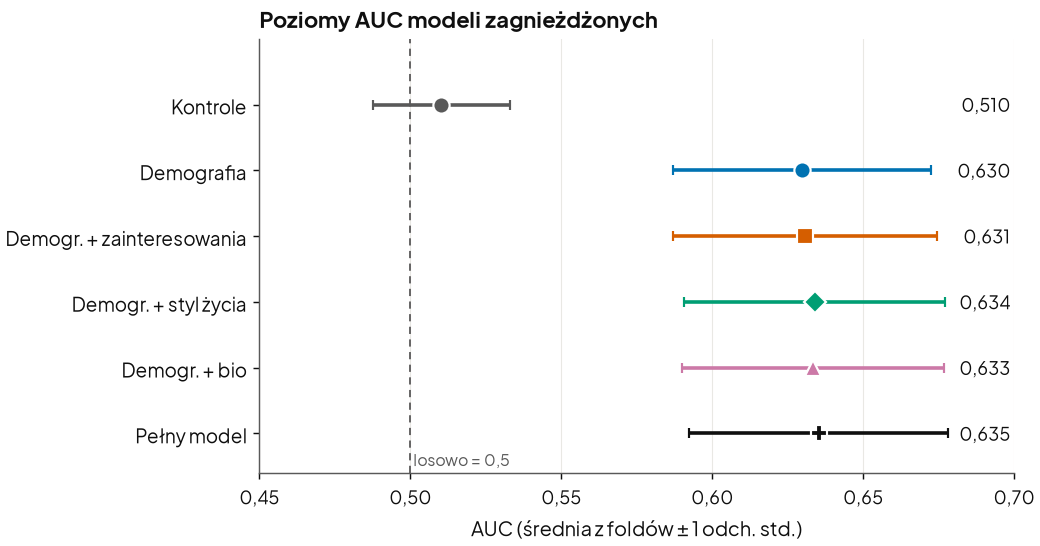

In [24]:
figure(uf.fig_levels(pair["levels"]))

**Tabela 5.** Poziomy AUC wszystkich modeli. *AUC z foldów* = średnia z 5 foldów i 3 podziałów (miara główna). *AUC z połączonych predykcji* = AUC na wszystkich predykcjach naraz (zaniżone przez różne intercepty foldów, tylko dla porównania). *Liczba parametrów* = współczynniki modelu razem ze stałą.

In [25]:
lv = pair["levels"].set_index("model")


def model_pl(k: str) -> str:
    if k in ("controls", "full"):
        return {"controls": "same kontrole", "full": "pełny (4 bloki)"}[k]
    nm = {
        "demography": "demografia",
        "interests": "zainteresowania",
        "lifestyle": "styl życia",
        "bio": "bio",
    }
    if k.startswith("only:"):
        return f"tylko {nm[k[5:]]}"
    if k.startswith("full-"):
        return f"pełny bez bloku „{nm[k[5:]]}”"
    return f"demografia + {nm[k[4:]]}"


levels_tab = pair["levels"].assign(
    Model=pair["levels"]["model"].map(model_pl),
    **{
        "AUC z foldów": pair["levels"]["auc_fold_mean"].map(lambda v: pl(v, 3)),
        "SD po foldach": pair["levels"]["auc_fold_sd"].map(lambda v: pl(v, 3)),
        "AUC z połączonych predykcji": pair["levels"]["auc_pooled"].map(lambda v: pl(v, 3)),
        "logloss": pair["levels"]["logloss"].map(lambda v: pl(v, 3)),
        "Liczba parametrów": pair["levels"]["n_params"],
    },
)
show(
    levels_tab[
        [
            "Model",
            "AUC z foldów",
            "SD po foldach",
            "AUC z połączonych predykcji",
            "logloss",
            "Liczba parametrów",
        ]
    ]
)
md(
    f"**Co to znaczy:** same kontrole dają AUC {pl(lv.loc['controls', 'auc_fold_mean'], 2)} "
    f"(poziom losowy), sama demografia {pl(lv.loc['only:demography', 'auc_fold_mean'], 2)}, "
    f"a model pełny {pl(lv.loc['full', 'auc_fold_mean'], 2)}. Model jest słaby w absolutnym "
    "sensie, a prawie całą jego wartość niesie demografia."
)

,Model,AUC z foldów,SD po foldach,AUC z połączonych predykcji,logloss,Liczba parametrów
0,same kontrole,"0,510","0,023","0,467","0,510",3
1,tylko demografia,"0,630","0,043","0,622","0,491",12
2,pełny bez bloku „demografia”,"0,536","0,017","0,516","0,509",12
3,tylko zainteresowania,"0,511","0,017","0,479","0,510",6
4,pełny bez bloku „zainteresowania”,"0,636","0,043","0,630","0,491",18
5,tylko styl życia,"0,525","0,017","0,497","0,510",7
6,pełny bez bloku „styl życia”,"0,634","0,044","0,627","0,491",17
7,tylko bio,"0,533","0,020","0,509","0,509",5
8,pełny bez bloku „bio”,"0,634","0,043","0,628","0,491",19
9,pełny (4 bloki),"0,635","0,043","0,630","0,491",21


**Co to znaczy:** same kontrole dają AUC 0,51 (poziom losowy), sama demografia 0,63, a model pełny 0,64. Model jest słaby w absolutnym sensie, a prawie całą jego wartość niesie demografia.

**Tabela 6.** Wiek a zainteresowania w jednolitym schemacie (AUC ponad same kontrole, średnia z 3 podziałów CV po nadawcach; bez przedziałów ufności, bo to rachunek pomocniczy bez bootstrapu). Daje pokrycie dla twierdzenia z H1, że duży przyrost bloku „wiek i zainteresowania” pochodzi z wieku.

In [26]:
AGE = ["same_band", "age_band_diff"]
INT = unified.block_columns("interests")


def auc(cols: list[str], group: str = "sender") -> np.ndarray:
    return unified.cv_auc_columns(d, cols, group=group, seeds=CV_SEEDS)


a0, a_age, a_int, a_both = auc([]), auc(AGE), auc(INT), auc(AGE + INT)
rows = [
    ("wiek (wiek i różnica wieku)", a_age - a0),
    ("zainteresowania (podobieństwo)", a_int - a0),
    ("wiek + zainteresowania", a_both - a0),
    ("zainteresowania ponad wiek", a_both - a_age),
]
age_tab = pd.DataFrame(
    {"Model": [r[0] for r in rows], "Przyrost AUC": [pl(r[1].mean(), 4, True) for r in rows]}
)
show(age_tab)
age_gain = (a_age - a0).mean()
int_over_age = (a_both - a_age).mean()
md(
    f"**Co to znaczy:** wiek sam daje {pl(age_gain, 4, True)}, zainteresowania "
    f"{pl((a_int - a0).mean(), 4, True)}, a po dodaniu zainteresowań do wieku przyrost to "
    f"{pl(int_over_age, 4, True)}. Duży przyrost „wieku i zainteresowań” w H1 pochodzi "
    "więc z wieku."
)

,Model,Przyrost AUC
0,wiek (wiek i różnica wieku),"+0,0688"
1,zainteresowania (podobieństwo),"+0,0010"
2,wiek + zainteresowania,"+0,0691"
3,zainteresowania ponad wiek,"+0,0003"


**Co to znaczy:** wiek sam daje +0,0688, zainteresowania +0,0010, a po dodaniu zainteresowań do wieku przyrost to +0,0003. Duży przyrost „wieku i zainteresowań” w H1 pochodzi więc z wieku.

### 4.4 Z czego składa się demografia
Wcześniejsze wyniki mogą sugerować, że siłą demografii jest „zgodność płci pary”. Sprawdzamy to rozkładając blok na części (ten sam schemat CV po nadawcach, AUC ponad same kontrole).

**Tabela 7.** Części bloku demografii. *Interakcja* (prawdziwa zgodność płci) = komórki pary minus same efekty główne płci nadawcy i odbiorcy. *Jak czytać:* im wyższy przyrost, tym więcej sama ta część wyjaśnia. Rachunek pomocniczy, bez przedziałów.

In [27]:
dp = unified.demography_decomposition(d, seeds=CV_SEEDS).set_index("part")
g = dp["gain_over_controls"]
K_MAIN = "płeć nadawcy + odbiorcy (efekty główne)"
K_CELLS = "komórki płci pary (efekty główne + interakcja)"
interaction = g[K_CELLS] - g[K_MAIN]
dp_tab = pd.DataFrame(
    {
        "Część": dp.index,
        "AUC": dp["auc"].map(lambda v: pl(v, 3)).to_numpy(),
        "Przyrost ponad kontrole": g.map(lambda v: pl(v, 4, True)).to_numpy(),
    }
)
show(dp_tab)
md(
    f"**Co to znaczy:** płeć nadawcy daje {pl(g['płeć nadawcy'], 4, True)}, płeć odbiorcy "
    f"{pl(g['płeć odbiorcy'], 4, True)}, razem {pl(g[K_MAIN], 4, True)}. Dodanie komórek pary, "
    f"czyli interakcji (właściwej zgodności płci), dokłada tylko {pl(interaction, 4, True)}. "
    f"Wiek sam daje {pl(g['wiek'], 4, True)}, płeć z wiekiem {pl(g.iloc[-1], 4, True)}. "
    "Demografia to więc głównie **płeć nadawcy i odbiorcy (różnice aktywności nadawców i "
    "popularności profili) oraz wiek**, a nie zgodność płci pary."
)

,Część,AUC,Przyrost ponad kontrole
0,kontrole (miasto),"0,510","+0,0000"
1,wiek,"0,579","+0,0688"
2,płeć nadawcy,"0,580","+0,0695"
3,płeć odbiorcy,"0,584","+0,0733"
4,płeć nadawcy + odbiorcy (efekty główne),"0,609","+0,0990"
5,komórki płci pary (efekty główne + interakcja),"0,611","+0,1005"
6,płeć (komórki) + wiek = demografia,"0,630","+0,1194"


**Co to znaczy:** płeć nadawcy daje +0,0695, płeć odbiorcy +0,0733, razem +0,0990. Dodanie komórek pary, czyli interakcji (właściwej zgodności płci), dokłada tylko +0,0015. Wiek sam daje +0,0688, płeć z wiekiem +0,1194. Demografia to więc głównie **płeć nadawcy i odbiorcy (różnice aktywności nadawców i popularności profili) oraz wiek**, a nie zgodność płci pary.

## 5. Odporność

### 5.1 Wariant `pair+receiver`
W wariancie podstawowym zainteresowania i styl życia są cechami **pary** (podobieństwo), a bio cechą **odbiorcy**, więc bloki nie są symetryczne. Wariant `pair+receiver` dodaje do zainteresowań i stylu życia cechy odbiorcy (liczba jego tagów, liczba znanych pól stylu życia).

**Rys. 5.** To samo co Rys. 3 dla wariantu `pair+receiver`. *Jak czytać:* jak Rys. 3. *Uwaga:* null nadal dotyczy przyrostu ponad demografię.

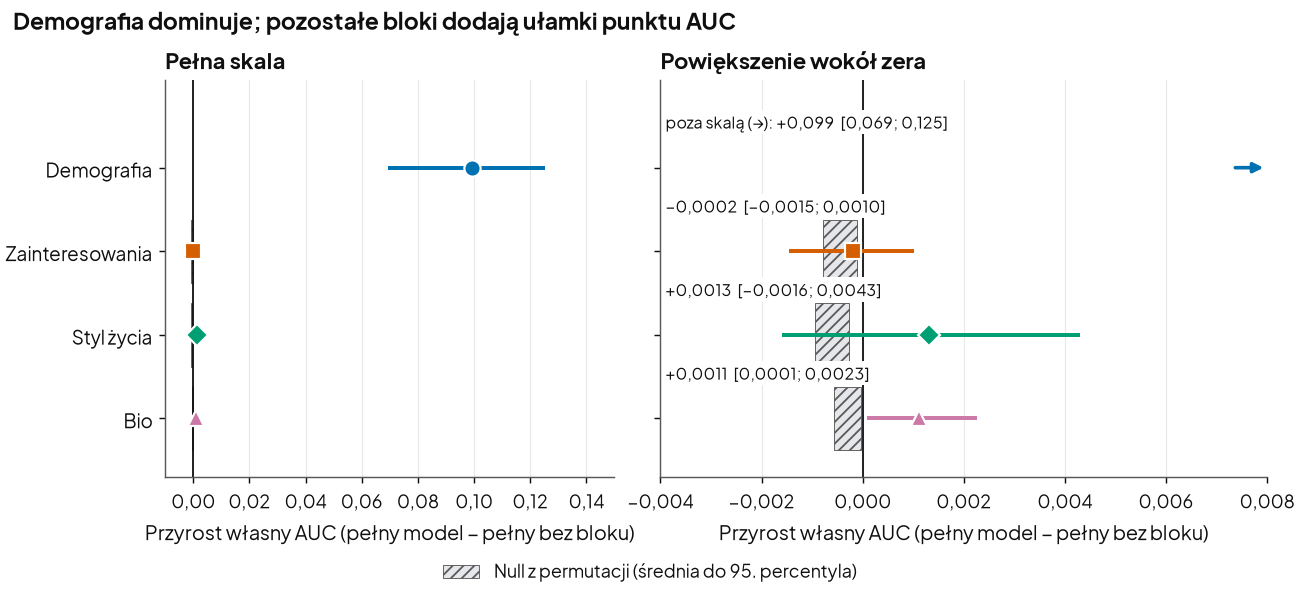

In [28]:
figure(uf.fig_block_increments(recv["contrasts"], recv["null"]))

**Tabela 8.** Porównanie wariantów (własny przyrost i przyrost ponad demografię). Bio nie ma dodatkowych cech odbiorcy (samo jest cechą odbiorcy), więc jego wiersze są takie same w obu wariantach.

In [29]:
cr = recv["contrasts"]
rows = []
for b, nm in NAMES.items():
    dem = b == "demography"
    rows.append(
        {
            "Blok": nm,
            "Własny, pair": cis(b, get(c, "unique", b)),
            "Własny, pair+receiver": cis(b, get(cr, "unique", b)),
            "Ponad demografię, pair": "—" if dem else cis(b, get(c, "over_demography", b)),
            "Ponad demografię, pair+receiver": (
                "—" if dem else cis(b, get(cr, "over_demography", b))
            ),
        }
    )
show(pd.DataFrame(rows))

,Blok,"Własny, pair","Własny, pair+receiver","Ponad demografię, pair","Ponad demografię, pair+receiver"
0,Demografia,"+0,099 [+0,068; +0,125]","+0,099 [+0,069; +0,125]",—,—
1,Zainteresowania,"−0,0004 [−0,0021; +0,0014]","−0,0002 [−0,0015; +0,0010]","+0,0010 [−0,0017; +0,0040]","+0,0028 [+0,0007; +0,0053]"
2,Styl życia,"+0,0018 [−0,0011; +0,0047]","+0,0013 [−0,0016; +0,0043]","+0,0042 [+0,0009; +0,0081]","+0,0041 [+0,0007; +0,0082]"
3,Bio,"+0,0014 [+0,0002; +0,0027]","+0,0011 [+0,0001; +0,0023]","+0,0038 [+0,0018; +0,0063]","+0,0038 [+0,0018; +0,0063]"


Które cechy zainteresowań robią tu różnicę? Rozdzielamy: podobieństwo pary (to z wariantu `pair`) i samą cechę odbiorcy (liczba zainteresowań na jego profilu, `interests_count_receiver`). Poniżej przyrost ponad demografię w trzech podziałach CV po nadawcach oraz (dla sprawdzenia przecieku) w CV po odbiorcach.

**Tabela 9.** Przyrost AUC ponad demografię dla wybranych zestawów cech: trzy podziały CV po nadawcach, ich średnia, oraz średnia (i zakres) z CV po odbiorcach. Rachunek pomocniczy, bez przedziałów; ten sam estymator co w Tab. 4.

In [30]:
DEM = unified.block_columns("demography")
SETS = {
    "zainteresowania: podobieństwo pary": unified.block_columns("interests"),
    "zainteresowania: tylko liczba u odbiorcy": ["interests_count_receiver"],
    "zainteresowania: pair+receiver": unified.block_columns("interests", "pair+receiver"),
    "styl życia (pair)": unified.block_columns("lifestyle"),
    "bio": unified.block_columns("bio"),
}
base_s, base_r = auc(DEM), auc(DEM, "receiver")
gain_s, gain_r, rows = {}, {}, []
for name, cols in SETS.items():
    gain_s[name] = auc(DEM + cols) - base_s
    gain_r[name] = auc(DEM + cols, "receiver") - base_r
    rows.append(
        {
            "Zestaw cech": name,
            **{f"CV po nadawcach, ziarno {i}": pl(v, 4, True) for i, v in enumerate(gain_s[name])},
            "Średnia (nadawcy)": pl(gain_s[name].mean(), 4, True),
            "CV po odbiorcach: średnia [min; max]": (
                f"{pl(gain_r[name].mean(), 4, True)} "
                f"[{pl(gain_r[name].min(), 4, True)}; {pl(gain_r[name].max(), 4, True)}]"
            ),
        }
    )
show(pd.DataFrame(rows))

,Zestaw cech,"CV po nadawcach, ziarno 0","CV po nadawcach, ziarno 1","CV po nadawcach, ziarno 2",Średnia (nadawcy),CV po odbiorcach: średnia [min; max]
0,zainteresowania: podobieństwo pary,"−0,0011","+0,0021","+0,0020","+0,0010","+0,0014 [+0,0012; +0,0015]"
1,zainteresowania: tylko liczba u odbiorcy,"+0,0021","+0,0034","+0,0060","+0,0038","+0,0014 [+0,0012; +0,0015]"
2,zainteresowania: pair+receiver,"+0,0013","+0,0025","+0,0045","+0,0028","+0,0018 [+0,0015; +0,0020]"
3,styl życia (pair),"+0,0029","+0,0041","+0,0056","+0,0042","+0,0034 [+0,0033; +0,0036]"
4,bio,"+0,0022","+0,0032","+0,0059","+0,0038","+0,0013 [+0,0012; +0,0014]"


In [ ]:
sim, cnt, mix = (gain_s[k].mean() for k in list(SETS)[:3])
i_recv = get(cr, "over_demography", "interests")
md(
    "**Co to znaczy:** *podobieństwo* zainteresowań nic nie dodaje ponad demografię "
    f"({pl(sim, 4, True)}). Dodaje natomiast **cecha odbiorcy** (liczba zainteresowań na jego "
    f"profilu): {pl(cnt, 4, True)} ponad demografię, czyli tyle co styl życia "
    f"({pl(gain_s['styl życia (pair)'].mean(), 4, True)}) i bio "
    f"({pl(gain_s['bio'].mean(), 4, True)}). Cały blok zainteresowań w wariancie `pair+receiver` "
    f"daje {ci(*i_recv, nd=4)}. To cecha odbiorcy (najpewniej kompletność profilu lub popularność "
    "— to nie jest przetestowane), a **nie treść czy podobieństwo zainteresowań**. Nie jest to "
    "też wynik bardzo stabilny: w CV po odbiorcach spada do "
    f"{pl(gain_r['zainteresowania: pair+receiver'].mean(), 4, True)}."
)

### 5.2 Scenariusze wrażliwości

**Rys. 6.** Własny przyrost AUC każdego bloku w sześciu scenariuszach. *Jak czytać:* jeden panel na blok, każdy z własną skalą osi; linia zerowa w każdym panelu. *Uwaga:* w scenariuszach jednej płci komórki płci nadawcy są stałe, więc demografia sprowadza się do płci odbiorcy, wieku i różnicy wieku; scenariusz „główny” liczono z jednym podziałem CV, więc minimalnie różni się od Tab. 4.

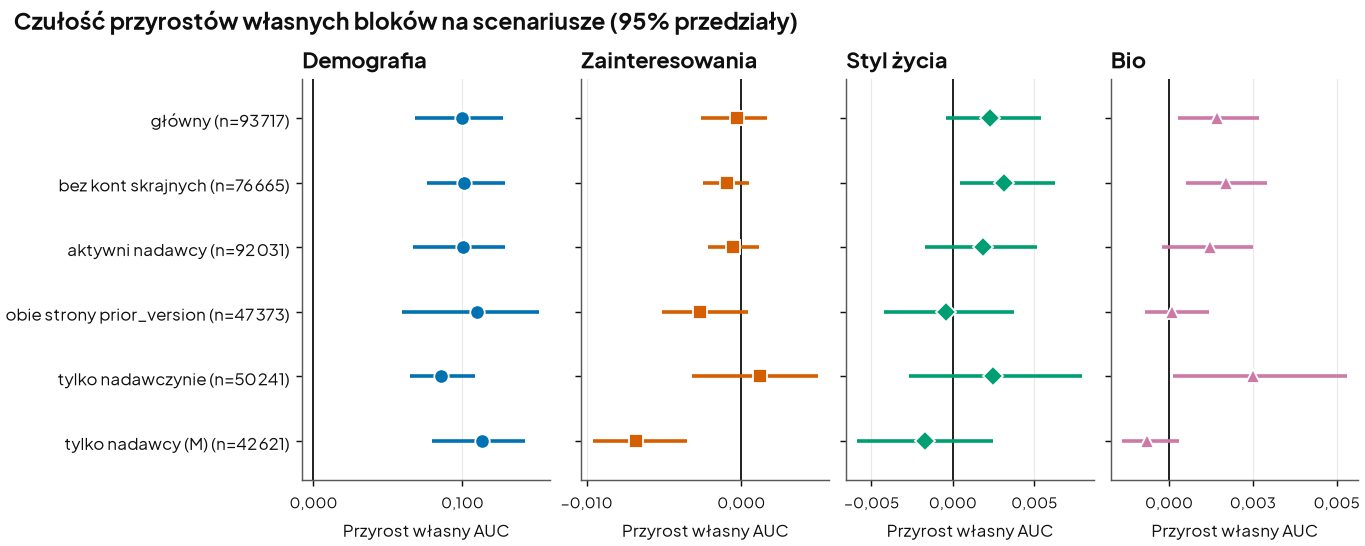

In [31]:
SC_PL = {
    "main": "główny",
    "no extreme accounts": "bez kont skrajnych",
    "active senders": "aktywni nadawcy",
    "both prior_version": "obie strony prior_version",
    "female senders only": "tylko nadawczynie",
    "male senders only": "tylko nadawcy (M)",
}
sens_pl = sens.assign(scenario=sens["scenario"].map(SC_PL))
figure(uf.fig_sensitivity(sens_pl))

**Tabela 10.** Zakres własnych przyrostów w scenariuszach i liczba scenariuszy z przedziałem wyłącznie nad zerem lub wyłącznie pod zerem.

In [32]:
rows = []
for b, nm in NAMES.items():
    sb = sens[sens["block"] == b]
    rows.append(
        {
            "Blok": nm,
            "Min": pl(sb.d_auc.min(), 4, True),
            "Max": pl(sb.d_auc.max(), 4, True),
            "Przedział nad zerem": f"{int((sb.ci_lo > 0).sum())} z {len(sb)}",
            "Przedział pod zerem": f"{int((sb.ci_hi < 0).sum())} z {len(sb)}",
        }
    )
show(pd.DataFrame(rows))


def sc(scen: str, blk: str) -> pd.Series:
    return sens[(sens["scenario"] == scen) & (sens["block"] == blk)].iloc[0]


male_i, pv_bio, pv_life = (
    sc("male senders only", "interests"),
    sc("both prior_version", "bio"),
    sc("both prior_version", "lifestyle"),
)
ALL_COLS = [x for b in unified.ALL_BLOCKS for x in unified.block_columns(b)]
NO_INT = [x for b in unified.ALL_BLOCKS if b != "interests" for x in unified.block_columns(b)]
male = d[d["sex_sender"] == "M"].reset_index(drop=True)
seeds6 = range(6)
male_seed = unified.cv_auc_columns(male, ALL_COLS, seeds=seeds6) - unified.cv_auc_columns(
    male, NO_INT, seeds=seeds6
)

,Blok,Min,Max,Przedział nad zerem,Przedział pod zerem
0,Demografia,"+0,0857","+0,1134",6 z 6,0 z 6
1,Zainteresowania,"−0,0068","+0,0012",0 z 6,1 z 6
2,Styl życia,"−0,0017","+0,0031",1 z 6,0 z 6
3,Bio,"−0,0006","+0,0025",3 z 6,0 z 6


In [33]:
md(
    "**Co to znaczy:** demografia dominuje w każdym scenariuszu, a małe bloki zmieniają się "
    "o kilka tysięcznych AUC i ich znak nie jest stabilny. Dwa scenariusze zasługują na uwagę. "
    f"(1) W „tylko nadawcy (M)” własny przyrost zainteresowań jest **ujemny**: "
    f"{ci(male_i.d_auc, male_i.ci_lo, male_i.ci_hi, nd=4)}, a z sześciu niezależnych podziałów CV "
    f"{int((male_seed < 0).sum())} z 6 daje wartość ujemną. Ujemny przyrost to przeuczenie "
    "dodanych kolumn, a jego powtarzalność wskazuje na heterogeniczność między nadawcami "
    "(zainteresowania działają inaczej w różnych grupach). "
    "(2) W „obie strony prior_version” (najczystsza reguła as-of) efekty znikają: bio "
    f"{pl(pv_bio.d_auc, 4, True)}, styl życia {pl(pv_life.d_auc, 4, True)}. Małe wkłady bio "
    "i stylu życia nie są więc odporne na jakość odtworzenia profilu z dnia swipe'a."
)

**Co to znaczy:** demografia dominuje w każdym scenariuszu, a małe bloki zmieniają się o kilka tysięcznych AUC i ich znak nie jest stabilny. Dwa scenariusze zasługują na uwagę. (1) W „tylko nadawcy (M)” własny przyrost zainteresowań jest **ujemny**: −0,0068 [−0,0096; −0,0035], a z sześciu niezależnych podziałów CV 6 z 6 daje wartość ujemną. Ujemny przyrost to przeuczenie dodanych kolumn, a jego powtarzalność wskazuje na heterogeniczność między nadawcami (zainteresowania działają inaczej w różnych grupach). (2) W „obie strony prior_version” (najczystsza reguła as-of) efekty znikają: bio +0,0001, styl życia −0,0004. Małe wkłady bio i stylu życia nie są więc odporne na jakość odtworzenia profilu z dnia swipe'a.

### 5.3 Null z przetasowania, zmienność między podziałami i CV po odbiorcach

**Tabela 11.** Null (wariant `pair`): obserwowany przyrost bloku ponad demografię i przyrost po przetasowaniu bloku. Obie wartości liczone na foldach **jednego** podziału (ziarno 0); `p = (1 + liczba nulli ≥ obserwowany) / (1 + n_perm)`, więc minimum to 1/(1+n_perm).

In [34]:
nn = pair["null"].set_index("block")
tabn = pd.DataFrame(
    {
        "Blok": [NAMES[b] for b in nn.index],
        "Średnia nulla": nn["null_mean"].map(lambda v: pl(v, 4, True)).to_numpy(),
        "p95 nulla": nn["null_p95"].map(lambda v: pl(v, 4, True)).to_numpy(),
        "Obserwowany (ziarno 0)": nn["observed_gain"].map(lambda v: pl(v, 4, True)).to_numpy(),
        "Średnia z 3 podziałów (Tab. 4)": [
            pl(get(c, "over_demography", b)[0], 4, True) for b in nn.index
        ],
        "p permutacyjne": nn["p_perm"].map(lambda v: pl(v, 3)).to_numpy(),
    }
)
show(tabn)

,Blok,Średnia nulla,p95 nulla,Obserwowany (ziarno 0),Średnia z 3 podziałów (Tab. 4),p permutacyjne
0,Zainteresowania,"−0,0007","−0,0000","−0,0011","+0,0010","0,861"
1,Styl życia,"−0,0008","−0,0002","+0,0029","+0,0042","0,005"
2,Bio,"−0,0006","−0,0000","+0,0022","+0,0038","0,005"


Jaki przyrost daje sama kolumna szumu? Dodajemy do demografii trzy kolumny z rozkładu normalnego (powtórzone kilka razy, jeden podział CV).

In [35]:
rng = np.random.default_rng(SEED)
t = d[[*DEM, *unified.CONTROLS, "y_right", "user_key"]].copy()
base0 = unified.cv_auc_columns(t, DEM, seeds=(0,))[0]
noise = []
for _ in range(6):
    zc = [f"z{j}" for j in range(3)]
    t[zc] = rng.normal(size=(len(t), 3))
    noise.append(unified.cv_auc_columns(t, DEM + zc, seeds=(0,))[0] - base0)
spread = max(max(gain_s[k]) - min(gain_s[k]) for k in ["styl życia (pair)", "bio"])
spread_i = max(gain_s["zainteresowania: podobieństwo pary"]) - min(
    gain_s["zainteresowania: podobieństwo pary"]
)
md(
    f"**Co to znaczy:** obserwowany przyrost w Tab. 11 pochodzi z jednego podziału i różni się od "
    "średniej z trzech podziałów (np. zainteresowania "
    f"{pl(nn.loc['interests', 'observed_gain'], 4, True)} "
    f"vs {pl(get(c, 'over_demography', 'interests')[0], 4, True)}), a zmienność między podziałami "
    f"(rozstęp {pl(spread_i, 4)} dla zainteresowań, {pl(spread, 4)} dla stylu życia "
    "i bio w Tab. 9) "
    "jest porównywalna z samymi efektami. Średnia nulla jest ujemna, bo **każda dodana kolumna "
    "szumu obniża AUC poza próbą**: trzy kolumny szumu dają średnio "
    f"{pl(np.mean(noise), 4, True)}. "
    "Dlatego „przekracza null” znaczy tu w praktyce „jest powyżej zera”, a p=0,005 to minimum "
    "możliwe przy 200 permutacjach. Pewne są więc tylko wnioski o rzędzie wielkości (kilka "
    "tysięcznych AUC), nie o kolejności małych bloków."
)

**Co to znaczy:** obserwowany przyrost w Tab. 11 pochodzi z jednego podziału i różni się od średniej z trzech podziałów (np. zainteresowania −0,0011 vs +0,0010), a zmienność między podziałami (rozstęp 0,0032 dla zainteresowań, 0,0037 dla stylu życia i bio w Tab. 9) jest porównywalna z samymi efektami. Średnia nulla jest ujemna, bo **każda dodana kolumna szumu obniża AUC poza próbą**: trzy kolumny szumu dają średnio −0,0007. Dlatego „przekracza null” znaczy tu w praktyce „jest powyżej zera”, a p=0,005 to minimum możliwe przy 200 permutacjach. Pewne są więc tylko wnioski o rzędzie wielkości (kilka tysięcznych AUC), nie o kolejności małych bloków.

### 5.4 Braki stylu życia: zero z flagą

Brak stylu życia zastąpiono zerem i dodano flagę `lifestyle_known_any` (czy znamy choć jedno pole pary). Sprawdzamy, jak duży to problem.

In [36]:
L_ALL = unified.block_columns("lifestyle")
L_NOFLAG = [x for x in L_ALL if x != "lifestyle_known_any"]
flag_share = d["lifestyle_known_any"].mean()
n_zero = int((d["lifestyle_known_any"] == 0).sum())
g_with = (auc(DEM + L_ALL) - base_s).mean()
g_wo = (auc(DEM + L_NOFLAG) - base_s).mean()
g_flag = (auc(DEM + ["lifestyle_known_any"]) - base_s).mean()
md(
    f"Flaga = 1 dla {100 * flag_share:.0f}% wierszy ({n_zero} wierszy z zerem), więc zastąpienie "
    "braków zerem dotyczy niewielkiej części próby i **nie przeszacowuje skali problemu**. "
    f"Przyrost stylu życia ponad demografię: {pl(g_with, 4, True)} z flagą, "
    f"{pl(g_wo, 4, True)} bez flagi, sama flaga {pl(g_flag, 4, True)}. Ostrożność o stylu życia "
    "wynika raczej z dominacji dwóch pól (sekcja 1) niż z zastępowania braków."
)

Flaga = 1 dla 99% wierszy (963 wierszy z zerem), więc zastąpienie braków zerem dotyczy niewielkiej części próby i **nie przeszacowuje skali problemu**. Przyrost stylu życia ponad demografię: +0,0042 z flagą, +0,0041 bez flagi, sama flaga +0,0007. Ostrożność o stylu życia wynika raczej z dominacji dwóch pól (sekcja 1) niż z zastępowania braków.

## 6. Czego to NIE pokazuje

- **Swipe ≠ match ani wynajem.** Mierzymy pierwszą deklarację zainteresowania, nie wzajemny wybór ani decyzję o wspólnym mieszkaniu.
- **Brak feedu i zdjęć.** Nie wiemy, kogo aplikacja pokazywała ani jak wyglądały zdjęcia, a one mogą być głównym sygnałem. „Demografia dominuje” dotyczy sygnałów, które mamy.
- **Bloki są niesymetryczne.** Demografia i zainteresowania (podobieństwo) to cechy pary, bio to cecha odbiorcy, styl życia to mieszanka. „Zainteresowania nic nie dodają” znaczy „ich *podobieństwo* nic nie dodaje”; cecha odbiorcy (liczba zainteresowań) dodaje tyle co styl życia i bio (5.1).
- **Płeć = aktywność nadawców + popularność profili (+ ewentualna preferencja).** Sama zgodność płci (interakcja) dodaje bardzo mało (4.4); wzór asymetryczny F/M jest eksploracyjny i miesza preferencję z popularnością.
- **Wąska próba.** Głównie Wrocław, wiek 18–20 lat dominuje; wnioski nie uogólniają się na inne grupy.
- **AUC pooled vs fold.** AUC z połączonych predykcji jest zaniżone (dla kontroli poniżej 0,5). Poziomy podajemy z foldów.
- **Bootstrap bez klastra odbiorców i CV tylko po nadawcach.** Przedziały uwzględniają zależność po nadawcy, nie po odbiorcy, a ci sami odbiorcy trafiają do foldów treningowych i testowych (możliwy przeciek popularności profili).

In [37]:
md(
    "- **Wyciek odbiorców (policzone).** W CV grupowanym po odbiorcach przyrost bio ponad "
    "demografię "
    f"spada z {pl(gain_s['bio'].mean(), 4, True)} do {pl(gain_r['bio'].mean(), 4, True)}, "
    "zainteresowań w `pair+receiver` z "
    f"{pl(gain_s['zainteresowania: pair+receiver'].mean(), 4, True)} do "
    f"{pl(gain_r['zainteresowania: pair+receiver'].mean(), 4, True)}, a stylu życia z "
    f"{pl(gain_s['styl życia (pair)'].mean(), 4, True)} do "
    f"{pl(gain_r['styl życia (pair)'].mean(), 4, True)} (Tab. 9; ten sam estymator w obu "
    "przypadkach). Część małych przyrostów to więc popularność znanych odbiorców, najsilniej "
    "u bio."
)

- **Wyciek odbiorców (policzone).** W CV grupowanym po odbiorcach przyrost bio ponad demografię spada z +0,0038 do +0,0013, zainteresowań w `pair+receiver` z +0,0028 do +0,0018, a stylu życia z +0,0042 do +0,0034 (Tab. 9; ten sam estymator w obu przypadkach). Część małych przyrostów to więc popularność znanych odbiorców, najsilniej u bio.

- **Korelacja, nie przyczynowość.** Brak wniosków o motywach.
- **Eksploracja.** Ujednolicony schemat zbudowano po obejrzeniu wyników H1–H3a; nie jest zarejestrowany z góry i nie rozstrzyga konfirmacyjnych H1 i H3a w ich prerejestrowanych metrykach.

## 7. Wnioski

Liczby poniżej są wyliczane z wyników powyżej (przedział 95%: bootstrap po nadawcach; rachunki pomocnicze z Tab. 6–9 bez przedziałów).

In [39]:
d_own, i_own, l_own, b_own = (get(c, "unique", b) for b in NAMES)
l_over, b_over, i_over = (get(c, "over_demography", b) for b in ["lifestyle", "bio", "interests"])
ld = dif.loc["lifestyle-interests"]
lvm = pair["levels"].set_index("model")["auc_fold_mean"]


def verdict(lo: float, hi: float) -> str:
    if lo <= 0 <= hi:
        return "przedział obejmuje zero"
    return "przedział nad zerem" if lo > 0 else "przedział pod zerem"


md(
    f"1. **Demografia niesie niemal całą wartość predykcyjną (spójne z tezą, eksploracyjnie).** "
    f"Własny przyrost AUC {ci(*d_own)}, o rząd wielkości więcej niż każdy inny blok (największy "
    f"z pozostałych: {pl(small_own, 4, True)}); sama demografia AUC "
    f"{pl(lvm['only:demography'], 2)}, "
    f"model pełny {pl(lvm['full'], 2)}, kontrole {pl(lvm['controls'], 2)}. To jednak **nie jest "
    f"zgodność płci pary**: płeć nadawcy i odbiorcy (aktywność nadawców i popularność profili) "
    f"dają razem {pl(g[K_MAIN], 4, True)}, wiek {pl(g['wiek'], 4, True)}, a interakcja "
    f"(właściwa zgodność) tylko {pl(interaction, 4, True)}. Osobne, eksploracyjne zdanie: wzór "
    f"jest asymetryczny (OR dla tej samej płci: nadawczynie {pl(OR.loc['F', 'or_adj'], 2)}, "
    f"nadawcy {pl(OR.loc['M', 'or_adj'], 2)}).\n"
    f"2. **Zainteresowania: część „dominują” nie ma poparcia, ale wynik zależy od "
    f"operacjonalizacji.** *Podobieństwo* zainteresowań nic nie dodaje: własny przyrost "
    f"{ci(*i_own, nd=4)} ({verdict(i_own[1], i_own[2])}), ponad demografię {ci(*i_over, nd=4)}, "
    f"ponad wiek {pl(int_over_age, 4, True)}. *Cecha odbiorcy* (liczba zainteresowań) dodaje ponad "
    f"demografię {pl(cnt, 4, True)} (w CV po odbiorcach spada do "
    f"{pl(gain_r['zainteresowania: tylko liczba u odbiorcy'].mean(), 4, True)}), czyli tyle, co "
    f"styl życia i bio. To cecha odbiorcy (kompletność profilu lub popularność), nie treść "
    f"zainteresowań; własny przyrost bloku nadal przy zerze.\n"
    f"3. **Styl życia i bio dodają bardzo mało (spójne z tezą), ale ten wynik jest kruchy.** "
    f"Własny przyrost: styl życia {ci(*l_own, nd=4)} ({verdict(l_own[1], l_own[2])}), bio "
    f"{ci(*b_own, nd=4)} ({verdict(b_own[1], b_own[2])}); ponad demografię {ci(*l_over, nd=4)} "
    f"i {ci(*b_over, nd=4)} (powyżej zera, rzędu kilku tysięcznych AUC). W scenariuszu "
    f"`both prior_version` efekty znikają (bio {pl(pv_bio.d_auc, 4, True)}, styl życia "
    f"{pl(pv_life.d_auc, 4, True)}), a w CV po odbiorcach bio spada do "
    f"{pl(gain_r['bio'].mean(), 4, True)}. Pomiar stylu życia jest niepełny (sekcja 1).\n"
    f"4. **Kolejność wśród małych bloków jest niepewna.** Różnica „styl życia − zainteresowania” "
    f"w przyrostach własnych: {ci(ld.d_auc, ld.ci_lo, ld.ci_hi, nd=4)} "
    f"({verdict(ld.ci_lo, ld.ci_hi)}), a zmienność między podziałami CV jest porównywalna "
    f"z efektami.\n"
    f"5. **Status tezy (eksploracyjnie, bez rozstrzygania konfirmacyjnych H1 i H3a):** spójne "
    f"z danymi jest „demografia dominuje, styl życia i bio dodają niewiele”, z zastrzeżeniem, "
    f"że demografia to płeć nadawcy i odbiorcy oraz wiek, a nie zgodność. Człon „zainteresowania "
    f"dominują” nie ma poparcia: podobieństwo zainteresowań nie dodaje nic, a cecha odbiorcy "
    f"dodaje tyle co styl życia i bio. Zakres: prawy swipe, korelacja, wąska próba."
)

NameError: name 'cnt' is not defined

## 8. Odtwarzalność

In [40]:
import contextlib
import importlib.metadata as im
import platform

pk = ["numpy", "pandas", "scipy", "matplotlib", "statsmodels", "scikit-learn", "threadpoolctl"]
ver = {}
for p in pk:
    with contextlib.suppress(im.PackageNotFoundError):
        ver[p] = im.version(p)
tm = meta["timing_s"]
md(f"- Python {platform.python_version()}, " + ", ".join(f"{k} {v}" for k, v in ver.items()) + ".")
md(
    f"- Ziarna: foldy CV {CV_SEEDS[0]}..{CV_SEEDS[-1]} (rachunki pomocnicze w notebooku: te same), "
    f"bootstrap: ziarno modułu + 1, szum w 5.3: SEED={SEED}. Parametry: n_boot={meta['n_boot']}, "
    f"n_perm={meta['n_perm']}, FAST={meta['fast']}."
)
md(
    f"- Czas zapisany w metadanych wyniku: {tm['total'] / 60:.1f} min (pełne liczenie bez "
    "cache). Czas tego uruchomienia: "
    f"{time.perf_counter() - T_START:.0f} s (rachunki pomocnicze w sekcjach 4.3–5.4 liczą się "
    "za każdym razem, bo nie są w cache)."
)

- Python 3.12.3, numpy 2.5.4, pandas 3.1.0, scipy 1.18.1, matplotlib 3.11.2, statsmodels 0.15.0, scikit-learn 1.9.1, threadpoolctl 3.8.0.

- Ziarna: foldy CV 0..2 (rachunki pomocnicze w notebooku: te same), bootstrap: ziarno modułu + 1, szum w 5.3: SEED=0. Parametry: n_boot=1000, n_perm=200, FAST=False.

- Czas zapisany w metadanych wyniku: 6.7 min (pełne liczenie bez cache). Czas tego uruchomienia: 443 s (rachunki pomocnicze w sekcjach 4.3–5.4 liczą się za każdym razem, bo nie są w cache).

- **Jak uruchomić:** `uv sync`, potem uruchomić notebook (jądro z `.venv`); wymaga lokalnych tabel w `data/interim/unified/` (poza gitem; zob. `data/README.md`). Pierwsze uruchomienie bez cache liczy ok. 6 minut. Rachunki pomocnicze używają funkcji `cv_auc_columns`, `receiver_folds` i `demography_decomposition` z `rentfriends.unified`.
- **Dane i prywatność:** żadne wiersze, klucze użytkowników ani bio nie są wyświetlane (strażnik `guard`); notebook jest commitowany bez outputów.
- **Ujawnienie użycia AI:** notebook powstał z pomocą agenta AI (Claude Code); szczegóły w `docs/ai-disclosure.md`, a logi sesji w `logs/ai/`. Liczby i wnioski należy zweryfikować przed użyciem w raporcie.